# 04 · Clustering

This notebook groups the articles into themes and looks at how close each theme is to the war. Those are two separate questions:

| Question | Answered by |
|---|---|
| Which articles belong together? (theme) | clustering on the Milne–Witten similarity between articles |
| How close is an article to the war? (closeness) | its similarity to the seed (`seed_similarity`) |

Article metadata (length, links, whether a template added the seed's link) is only used to describe the clusters, not to form them. Length would group articles by size instead of topic, and `from_template` would just rebuild the navboxes. Leaving it out also makes it possible to check afterwards whether the clusters are navboxes in disguise.

The seed is left out (788 articles), since it's linked to everything and would be every article's neighbor. The clustering code is in `src/clustering.py`.

In [1]:
import re
import sys
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from scipy.cluster.hierarchy import fcluster, linkage
from scipy.spatial.distance import squareform
from sklearn.metrics import adjusted_rand_score, silhouette_score

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import clustering
import similarity
import wiki

pd.set_option("display.max_colwidth", 120)
SEED = "Hundred Years' War"
K = 10  # neighbors per article in the graph

data = ROOT / "data" / "processed"
pairs = pd.read_parquet(data / "pairs.parquet")
pairs = pairs[(pairs["a"] != SEED) & (pairs["b"] != SEED)]
mw = similarity.from_pairs(pairs, "milne_witten")
distance = 1 - mw.to_numpy()
print(f"Milne–Witten similarity: {mw.shape[0]} × {mw.shape[1]} articles (seed excluded)")

Milne–Witten similarity: 788 × 788 articles (seed excluded)


## 1. The neighbor graph

Almost every pair of articles has some similarity (the in-link half alone has a median of 0.49), so a graph using all 310,000 pairs would be one dense ball. Instead each article keeps only its K = 10 most similar articles (a k-nearest-neighbor graph), with edges weighted by similarity. An edge stays if either end picked it, so popular articles can end up with more than 10 edges.

K controls how fine the grouping is. Fewer neighbors split the graph into more, smaller groups. Section 3 checks how sensitive the result is to K.

In [2]:
graph = clustering.knn_graph(mw, K)
degree = pd.Series(dict(graph.degree()))
print(f"{graph.number_of_nodes()} articles | {graph.number_of_edges():,} edges | "
      f"{nx.number_connected_components(graph)} connected component(s)")
print(f"edges per article: median {degree.median():.0f}, max {degree.max()} ({degree.idxmax()})")

788 articles | 6,243 edges | 1 connected component(s)
edges per article: median 13, max 74 (Hastilude)


## 2. Louvain communities

Louvain is a standard algorithm for finding communities in a graph, i.e. groups of nodes with more edge weight inside than between them. It maximizes modularity: the edge weight inside groups minus what you'd expect if the same edges were placed at random. Unlike k-means, it picks the number of groups on its own.

Below, each cluster is listed with its 6 most central articles (highest average similarity to the rest of the cluster).

In [3]:
labels = clustering.louvain(graph)
centrality = pd.Series(
    {t: mw.loc[t, labels.index[labels == c]].drop(t).mean() for t, c in labels.items()}, name="centrality"
)

def top_members(c, n=6):
    members = centrality[labels == c].sort_values(ascending=False)
    return " | ".join(members.index[:n])

print(f"{labels.nunique()} clusters")
pd.DataFrame({
    "articles": labels.value_counts().sort_index(),
    "most central articles": [top_members(c) for c in sorted(labels.unique())],
})

12 clusters


,articles,most central articles
cluster,,
0,120,"Battle of Caen (1346) | Hundred Years' War, 1345–1347 | Crécy campaign | Battle of Blanchetaque | Battle of Ardres |..."
1,119,High Middle Ages | History of Western civilization | Late Middle Ages | Early Middle Ages | Crusading movement | Ris...
2,88,Henry IV of England | House of Plantagenet | Richard II of England | Henry V of England | List of English monarchs |...
3,78,Hastilude | Disability in the Middle Ages | Great Famine of 1315–1317 | Itinerant court | List of common misconcepti...
4,67,"Name of Joan of Arc | Trial of Joan of Arc | I, Joan | Equestrian statue of Joan of Arc (Paris) | Jacques d'Arc | Pi..."
5,63,Second Hundred Years' War | Anglo-French Wars | Battle of Brémule | Gascon War | Anglo-French War (1627–1629) | Angl...
6,63,Siege of Saint-Denis (1435) | Siege of Rouen (1418–1419) | Battle of Patay | Siege of Paris (1435–1436) | Battle of ...
7,59,Battle of Auray | Battle of Cocherel | Battle of La Rochelle | Battle of Pontvallain | Siege of Rennes (1356–1357) |...
8,58,Charles IV of France | Philip V of France | Louis X of France | Philip VI of France | John II of France | John I of ...


### Naming the clusters

A name should fit the whole cluster and not just its best-known members. The 6 central articles above show the core of each cluster, but a large cluster can have a second group sitting at its edges that the core doesn't show. So I looked at five things for each cluster:

1. its 10 most central articles
2. its make-up by article type (from notebook 03: hand labels where I have them, predicted from the text otherwise; the types only describe the clusters and aren't used to form them)
3. the most common words in its members' short descriptions
4. its least central members, which show what the cluster picked up at its edges
5. how many of its members are listed in one navbox

In [4]:
articles = pd.read_parquet(data / "articles.parquet").set_index("title")
types = pd.read_parquet(data / "article_types.parquet").set_index("title")["type"]
links = pd.read_parquet(data / "links.parquet")
STOPWORDS = {"from", "with", "that", "during", "between", "part", "century", "which"}

def description_words(titles, n=6):
    """The most frequent words in the members' short descriptions."""
    words = Counter(w for text in articles.loc[titles, "shortdesc"].fillna("")
                    for w in re.findall(r"[a-z]+", text.lower()) if len(w) > 3 and w not in STOPWORDS)
    return ", ".join(w for w, _ in words.most_common(n))

def ranked(c):
    """A cluster's members, most central first."""
    return centrality[labels == c].sort_values(ascending=False)

rows = {}
for c in sorted(labels.unique()):
    members = ranked(c)
    counts = types[members.index].value_counts()
    rows[members.index[0]] = {
        "articles": len(members),
        "10 most central": " | ".join(members.index[:10]),
        "main types": "; ".join(f"{t} {n}" for t, n in counts.head(3).items()),
        "description words": description_words(members.index),
        "least central": " | ".join(members.index[-4:]),
    }
evidence = pd.DataFrame(rows).T.rename_axis("cluster (most central article)")
evidence

,articles,10 most central,main types,description words,least central
cluster (most central article),,,,,
Battle of Caen (1346),120,"Battle of Caen (1346) | Hundred Years' War, 1345–1347 | Crécy campaign | Battle of Blanchetaque | Battle of Ardres |...",scholarship and media 56; battles and sieges 37; historical people 7,"hundred, years, historian, british, battle, english",Harvard University Press | University of California Press | Wikisource | Yale University Press
High Middle Ages,119,High Middle Ages | History of Western civilization | Late Middle Ages | Early Middle Ages | Crusading movement | Ris...,"periods, culture and religion 59; dynasties and polities 41; wars and campaigns 6","period, state, europe, european, history, italian",2022 Russian invasion of Ukraine | University of Paris | Louvre | World War I
Henry IV of England,88,Henry IV of England | House of Plantagenet | Richard II of England | Henry V of England | List of English monarchs |...,historical people 42; wars and campaigns 11; dynasties and polities 9,"england, english, king, queen, scotland, battle",Great Britain | Treaty of Corbeil (1326) | British Library | Cardiff University
Hastilude,78,Hastilude | Disability in the Middle Ages | Great Famine of 1315–1317 | Itinerant court | List of common misconcepti...,"periods, culture and religion 48; dynasties and polities 13; institutions, titles and concepts 5","middle, ages, medieval, europe, state, european",Representation of animals in Western medieval art | Speculum (journal) | Medieval English wool trade | Plague (disease)
Name of Joan of Arc,67,"Name of Joan of Arc | Trial of Joan of Arc | I, Joan | Equestrian statue of Joan of Arc (Paris) | Jacques d'Arc | Pi...",scholarship and media 43; historical people 13; battles and sieges 6,"french, film, joan, hundred, years, opera",Pierre Cauchon | Gilles de Rais | André César Vermare | History Channel
Second Hundred Years' War,63,Second Hundred Years' War | Anglo-French Wars | Battle of Brémule | Gascon War | Anglo-French War (1627–1629) | Angl...,wars and campaigns 36; events and treaties 11; battles and sieges 6,"french, france, england, wars, conflict, british",French nationalism | World War II | French language | Cold War
Siege of Saint-Denis (1435),63,Siege of Saint-Denis (1435) | Siege of Rouen (1418–1419) | Battle of Patay | Siege of Paris (1435–1436) | Battle of ...,battles and sieges 42; historical people 12; wars and campaigns 3,"hundred, years, battle, english, siege, france","Richard Beauchamp, 13th Earl of Warwick | Bernard VII of Armagnac | Harfleur | Jean Favier"
Battle of Auray,59,Battle of Auray | Battle of Cocherel | Battle of La Rochelle | Battle of Pontvallain | Siege of Rennes (1356–1357) |...,battles and sieges 30; historical people 12; events and treaties 4,"hundred, years, battle, breton, succession, brittany",Norfolk Record Office | Dinan | Hearth tax | Sydney F. Wise
Charles IV of France,58,Charles IV of France | Philip V of France | Louis X of France | Philip VI of France | John II of France | John I of ...,"historical people 28; institutions, titles and concepts 14; dynasties and polities 9","france, king, french, navarre, title, royal",Baron | Bibliothèque nationale de France | Dysentery | Nemo dat quod non habet


#### Example 1: a clean cluster, the Lancastrian phase

This is the cluster around *Siege of Rouen (1418–1419)*. Below are its 10 most central articles and the links they have in common. The similarity score itself can't show this, because it's an average of percentile ranks and maxes out near 1 at the top (every pair among these 10 scores about 0.99).

In [5]:
def describe_top(member, n=10):
    """The n most central articles of `member`'s cluster, with their description and type."""
    top = ranked(labels[member]).index[:n]
    return pd.DataFrame({"short description": articles.loc[top, "shortdesc"], "type": types[top],
                         "centrality": centrality[top].round(3)})

def shared_links(member, n_top=10, n_show=8):
    """What the cluster's n_top most central articles have in common: the articles all of them link to."""
    top = ranked(labels[member]).index[:n_top]
    out = links[links["source"].isin(top) & (links["target"] != SEED)]
    linked_by = out.groupby("target")["source"].nunique()
    common = linked_by.index[linked_by == n_top]
    via_template = out[out["target"].isin(common)]["from_template"].mean()
    print(f"{len(common)} articles are linked from all {n_top} ({common.isin(ranked(labels[member]).index).sum()} of them "
          f"in the same cluster); {via_template:.0%} of those links come from a template "
          f"(vs {out['from_template'].mean():.0%} of all their links)")
    template_share = out[out["target"].isin(common)].groupby("target")["from_template"].mean()
    return pd.DataFrame({"added by a template": template_share.map("{:.0%}".format)}).head(n_show)

def pairwise(titles):
    v = mw.loc[titles, titles].to_numpy()
    return v[np.triu_indices(len(titles), 1)].mean()

LANCASTRIAN = "Siege of Rouen (1418–1419)"
display(describe_top(LANCASTRIAN))
display(shared_links(LANCASTRIAN))
members = ranked(labels[LANCASTRIAN]).index
print(f"Average similarity between pairs: 10 most central {pairwise(members[:10]):.2f}, "
      f"10 least central {pairwise(members[-10:]):.2f}, all pairs of articles {pairwise(mw.index):.2f}")

,short description,type,centrality
Siege of Saint-Denis (1435),Conflict in Hundred Years' War,battles and sieges,0.971
Siege of Rouen (1418–1419),English siege in the Hundred Years' War,battles and sieges,0.970
Battle of Patay,1429 battle during the Hundred Years' War,battles and sieges,0.969
Siege of Paris (1435–1436),Conflict in Hundred Years' War,battles and sieges,0.969
Battle of Verneuil,1424 battle of the Hundred Years' War,battles and sieges,0.966
Battle of Gerberoy,Battle of the Hundred Years' War,battles and sieges,0.966
Battle of the Herrings,"1429 battle of the Hundred Years' War in Rouvray, France",battles and sieges,0.966
Siege of Harfleur,Siege in 1415,battles and sieges,0.966
Battle of La Brossinière,Battle during the Hundred Years' War,battles and sieges,0.965
"Hundred Years' War, 1415–1453",Third phase of the Hundred Years' War,wars and campaigns,0.965


42 articles are linked from all 10 (30 of them in the same cluster); 92% of those links come from a template (vs 56% of all their links)


,added by a template
target,
1383–1385 Portuguese interregnum,100%
Armagnac–Burgundian Civil War,80%
Battle of Agincourt,40%
Battle of Baugé,80%
Battle of Beaugency (1429),80%
Battle of Blanquefort,100%
Battle of Castillon,90%
Battle of Cravant,80%


Average similarity between pairs: 10 most central 0.99, 10 least central 0.70, all pairs of articles 0.50


These 10 articles look alike because they carry the same link lists, and almost all of the links they share were added by templates. Campaignboxes and the war's navbox list the phase's battles and sieges, and every one of those pages carries them. So the cluster is coherent, but part of that comes from the templates themselves.

#### Example 2: looking past the top 10, the Edwardian phase

This is the cluster around *Crécy campaign*. Its 10 most central articles are all battles and campaigns from 1337–1360, so the core looks like the Edwardian phase. But the cluster has 120 articles, and almost half of them are scholarship and media: historians, university presses, Wikisource. They sit at the edge of the cluster, and their nearest neighbors are mostly each other, so it's really a second group that got merged into this one.

,short description,type,centrality
Battle of Caen (1346),Battle during the Hundred Years' War,battles and sieges,0.769
"Hundred Years' War, 1345–1347",Series of European military campaigns,wars and campaigns,0.756
Crécy campaign,1346–1347 military campaign during the Hundred Years' War,battles and sieges,0.752
Battle of Blanchetaque,Battle during the Hundred Years' War,battles and sieges,0.746
Battle of Ardres,Battle during the Hundred Years' War,battles and sieges,0.746
Battle of Lunalonge,1349 battle of the Hundred Years' War,battles and sieges,0.742
Battle of Winchelsea,1350 naval battle of the Hundred Years' War,battles and sieges,0.741
Siege of Calais (1346–1347),Siege by King Edward III during the Hundred Years' War,battles and sieges,0.739
Battle of Auberoche,Battle during the Hundred Years' War (1345),battles and sieges,0.739
Gascon campaign of 1345,Military campaign during the Hundred Years' War,battles and sieges,0.737


,articles,median position (1 = most central)
type,,
battles and sieges,37,24.0
wars and campaigns,4,28.0
events and treaties,6,30.5
military concepts and technology,3,53.0
historical people,7,58.0
places,6,72.0
scholarship and media,56,90.5
other,1,104.0


The 56 scholarship articles' 10 nearest articles: 61% are scholarship and media too


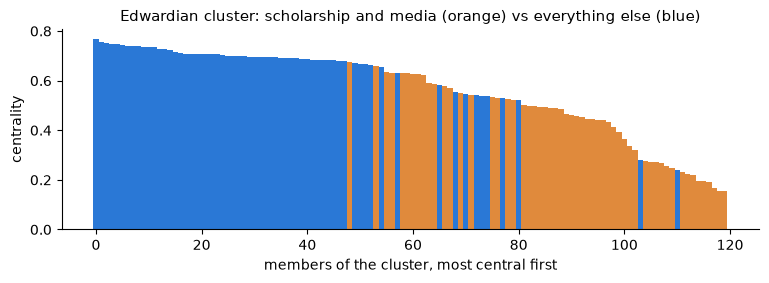

In [6]:
EDWARDIAN = "Crécy campaign"
display(describe_top(EDWARDIAN))

members = ranked(labels[EDWARDIAN])
position = pd.Series(np.arange(1, len(members) + 1), index=members.index)  # 1 = most central
make_up = pd.DataFrame({"articles": types[members.index].value_counts(),
                        "median position (1 = most central)": position.groupby(types[members.index]).median()})
display(make_up.sort_values("median position (1 = most central)"))

scholarship = members.index[types[members.index] == "scholarship and media"]
nearest = mw.index.to_numpy()[clustering.neighbors(mw, K)]
neighbor_types = types[nearest[[mw.index.get_loc(t) for t in scholarship]].ravel()]
print(f"The {len(scholarship)} scholarship articles' 10 nearest articles: "
      f"{(neighbor_types == 'scholarship and media').mean():.0%} are scholarship and media too")

fig, ax = plt.subplots(figsize=(9, 2.6))
is_scholarship = types[members.index].eq("scholarship and media").to_numpy()
ax.bar(np.arange(len(members)), members.to_numpy(), width=1,
       color=np.where(is_scholarship, "#e08a3c", "#2a78d6"))
ax.set_xlabel("members of the cluster, most central first")
ax.set_ylabel("centrality")
ax.set_title("Edwardian cluster: scholarship and media (orange) vs everything else (blue)", fontsize=11)
ax.spines[["top", "right"]].set_visible(False);

#### Clusters that rebuild a navbox

Articles in the same navbox all carry the same block of links, so Milne–Witten sees them as similar, even though the clustering never knows which links came from templates. This table counts how many members of each cluster are listed in the war's four navboxes. (The navbox contents were fetched later than the rest of the data, so they may have changed slightly since October.)

In [7]:
NAVBOXES = ["Middle Ages", "History of Europe", "Joan of Arc", "Hundred Years' War"]
navbox = {b: set(wiki.get_template_links(b)) for b in NAVBOXES}
overlap = pd.DataFrame({b: {members.index[0]: members.index.isin(list(navbox[b])).sum()
                            for members in (ranked(c) for c in sorted(labels.unique()))}
                        for b in NAVBOXES})
overlap.insert(0, "articles", evidence["articles"])
overlap.sort_values("articles", ascending=False)

,articles,Middle Ages,History of Europe,Joan of Arc,Hundred Years' War
Battle of Caen (1346),120,0,0,0,5
High Middle Ages,119,32,93,0,0
Henry IV of England,88,4,1,0,7
Hastilude,78,75,1,0,0
Name of Joan of Arc,67,0,0,63,1
Second Hundred Years' War,63,2,2,0,1
Siege of Saint-Denis (1435),63,0,0,2,18
Battle of Auray,59,0,0,0,2
Charles IV of France,58,1,1,1,5
Bourges,30,0,0,0,0


#### The names

| Cluster (most central) | Name | Why |
|---|---|---|
| Siege of Saint-Denis (1435) | Lancastrian phase (1415–1453) | battles and sieges of 1415–1453 (Example 1) |
| Battle of Caen (1346) | **Edwardian phase (1337–1360) and cited scholarship** | battles of 1337–1360 at the core, plus 56 historians, presses and sources at the edge (Example 2) |
| Battle of Auray | Brittany and the Caroline phase (1369–1389) | the Breton War of Succession, du Guesclin, Castile |
| Name of Joan of Arc | **Joan of Arc and her legacy** | 43 of 67 are films, operas, plays and statues about her; navbox-driven |
| Henry IV of England | English monarchy | English kings, the Plantagenets, wars in Scotland and Wales |
| Charles IV of France | French monarchy and feudalism | Capetian and Valois kings, plus titles and institutions |
| Charles the Bold | Burgundy and the Low Countries | the Valois dukes of Burgundy, Flemish towns |
| Second Hundred Years' War | **Anglo-French conflicts beyond the war** | Anglo-French wars before and after 1337–1453, out to the 20th century |
| High Middle Ages | The Middle Ages in Europe | periods and states; mostly the *History of Europe* navbox |
| Hastilude | Medieval society and culture | daily life, culture and religion; almost all the *Middle Ages* navbox |
| Bourges | Towns and regions | French towns and regions |
| Siege | War in general | military concepts: siege, artillery, proxy war |

Names in bold were changed after looking past each cluster's core. Every cluster also has a few weak members at its edge (like *Dysentery* in French monarchy). Louvain puts every article in some cluster, with no option to leave one out.

In [8]:
NAMES = {
    "Crécy campaign": "Edwardian phase (1337–1360) and cited scholarship",
    "Siege of Rouen (1418–1419)": "Lancastrian phase (1415–1453)",
    "War of the Breton Succession": "Brittany and the Caroline phase (1369–1389)",
    "Trial of Joan of Arc": "Joan of Arc and her legacy",
    "Henry V of England": "English monarchy",
    "Philip VI of France": "French monarchy and feudalism",
    "Burgundian State": "Burgundy and the Low Countries",
    "Anglo-French Wars": "Anglo-French conflicts beyond the war",
    "High Middle Ages": "The Middle Ages in Europe",
    "Hastilude": "Medieval society and culture",
    "Bordeaux": "Towns and regions",
    "Medieval warfare": "War in general",
}
cluster_name = {labels[article]: name for article, name in NAMES.items()}
assert len(cluster_name) == len(NAMES) == labels.nunique(), "every cluster needs exactly one name"
names = labels.map(cluster_name).rename("cluster_name")
names.value_counts().to_frame("articles")

,articles
cluster_name,
Edwardian phase (1337–1360) and cited scholarship,120
The Middle Ages in Europe,119
English monarchy,88
Medieval society and culture,78
Joan of Arc and her legacy,67
Lancastrian phase (1415–1453),63
Anglo-French conflicts beyond the war,63
Brittany and the Caroline phase (1369–1389),59
French monarchy and feudalism,58


## 3. Evaluation

There are no labels to score against, so I use three checks instead:

- Separation (silhouette): for each article, compare its average distance to its own cluster with its average distance to the nearest other cluster. It runs from −1 to 1, higher is better separated. Distance = 1 − similarity.
- Stability: rerun with different random seeds, and on random 80% subsets. Do the same groups come back?
- Robustness: do the groups hold up with a different K?

Agreement between two clusterings is measured with the adjusted Rand index (ARI): 1 for identical groupings, around 0 for chance. Cluster numbering doesn't matter to it.

### Silhouette
For comparison I also run hierarchical clustering, which works on the distances directly and keeps merging the two closest groups. Average linkage measures the distance between groups by the average pair, complete linkage by the farthest pair.

In [9]:
condensed = squareform(distance, checks=False)
louvain_labels = labels[mw.index].to_numpy()
n = labels.nunique()

candidates = {"Louvain": louvain_labels}
for method, k in [("average", 5), ("average", n), ("complete", n)]:
    candidates[f"hierarchical, {method} linkage, {k} clusters"] = fcluster(linkage(condensed, method), k, "maxclust")

def summarize(cluster_labels):
    sizes = np.sort(np.bincount(cluster_labels))[::-1]
    sizes = sizes[sizes > 0]
    return {
        "silhouette": silhouette_score(distance, cluster_labels, metric="precomputed"),
        "largest cluster": sizes[0],
        "clusters of 1": (sizes == 1).sum(),
        "ARI vs Louvain": adjusted_rand_score(louvain_labels, cluster_labels),
    }

pd.DataFrame({name: summarize(c) for name, c in candidates.items()}).T.round(2)

,silhouette,largest cluster,clusters of 1,ARI vs Louvain
Louvain,0.21,120.0,0.0,1.00
"hierarchical, average linkage, 5 clusters",0.28,765.0,2.0,-0.00
"hierarchical, average linkage, 12 clusters",0.17,695.0,4.0,0.02
"hierarchical, complete linkage, 12 clusters",0.21,298.0,0.0,0.30


Average linkage with 5 clusters gets the best silhouette, but it puts almost every article into one cluster. Silhouette rewards splitting a few distant outliers off a big group, so it can't be the only check. Louvain's silhouette is modest because the themes overlap (a king belongs to his dynasty and to his battles), and silhouette measures how cleanly clusters separate, not whether they make sense. Complete linkage matches Louvain's silhouette but still has one cluster of almost 300 articles and only partly agrees with Louvain. I went with Louvain because its groups are readable themes and, as the next section shows, stable.

### Stability and robustness

In [10]:
by_seed = [clustering.louvain(graph, seed=s) for s in range(1, 11)]
by_subset = clustering.stability(mw, labels, K, n_runs=20, frac=0.8)
by_k = {k: clustering.louvain(clustering.knn_graph(mw, k)) for k in (5, 15)}

pd.DataFrame({
    "ARI vs main clustering": [
        np.mean([adjusted_rand_score(labels, s[labels.index]) for s in by_seed]),
        by_subset.mean(),
        adjusted_rand_score(labels, by_k[5][labels.index]),
        adjusted_rand_score(labels, by_k[15][labels.index]),
    ],
    "clusters": [
        f"{min(s.nunique() for s in by_seed)}–{max(s.nunique() for s in by_seed)}",
        "",
        by_k[5].nunique(),
        by_k[15].nunique(),
    ],
}, index=["10 other random seeds (mean)", "20 random 80% subsets (mean)", "K = 5 neighbors", "K = 15 neighbors"]).round(2)

,ARI vs main clustering,clusters
10 other random seeds (mean),0.89,11–13
20 random 80% subsets (mean),0.79,
K = 5 neighbors,0.65,16
K = 15 neighbors,0.77,11


## 4. Cluster profiles

Here the metadata comes in, to describe each theme:

- median seed rank: the median of the cluster's ranks in similarity to the seed (1 = most similar, out of 788)
- linked from a template: share of the cluster the seed links to only through a template
- links back to the seed: share of the cluster whose page links to the war
- median words: article length

In [11]:
articles = pd.read_parquet(data / "articles.parquet").set_index("title")
seed_similarity = pd.read_parquet(data / "seed_similarity.parquet").set_index("title")
links = pd.read_parquet(data / "links.parquet")
seed_links = links[links["source"] == SEED].drop_duplicates("target").set_index("target")

profile_data = pd.DataFrame({
    "cluster_name": names,
    "seed_rank": seed_similarity["milne_witten_rank"],
    "from_template": seed_links["from_template"].astype(float),
    "links_to_seed": articles["links_to_seed"].astype(float),
    "word_count": articles["word_count"],
}).loc[labels.index]

profile = profile_data.groupby("cluster_name").agg(**{
    "articles": ("seed_rank", "size"),
    "median seed rank": ("seed_rank", "median"),
    "linked from a template": ("from_template", "mean"),
    "links back to the seed": ("links_to_seed", "mean"),
    "median words": ("word_count", "median"),
}).sort_values("median seed rank")
profile.round(2)

,articles,median seed rank,linked from a template,links back to the seed,median words
cluster_name,,,,,
Lancastrian phase (1415–1453),63,229.0,0.54,0.90,870.0
Medieval society and culture,78,253.5,0.94,0.85,3388.0
Joan of Arc and her legacy,67,257.0,0.88,0.96,675.0
The Middle Ages in Europe,119,356.0,0.82,0.82,6667.0
Brittany and the Caroline phase (1369–1389),59,408.0,0.44,0.73,1043.0
English monarchy,88,478.5,0.22,0.41,3382.5
Anglo-French conflicts beyond the war,63,482.0,0.78,0.62,2701.0
French monarchy and feudalism,58,495.0,0.14,0.50,1550.5
Burgundy and the Low Countries,23,528.0,0.35,0.39,1683.0


## 5. The picture

A force-directed layout draws the neighbor graph with each edge as a spring whose strength is the pair's similarity, while all nodes repel each other. The positions are a 2D squeeze of the full similarity table and change with the random start, so only local neighborhoods mean anything, not distances across the whole picture.

12 colors would be hard to tell apart, so the layout is drawn 12 times, each one highlighting a single cluster with its most central article labeled.

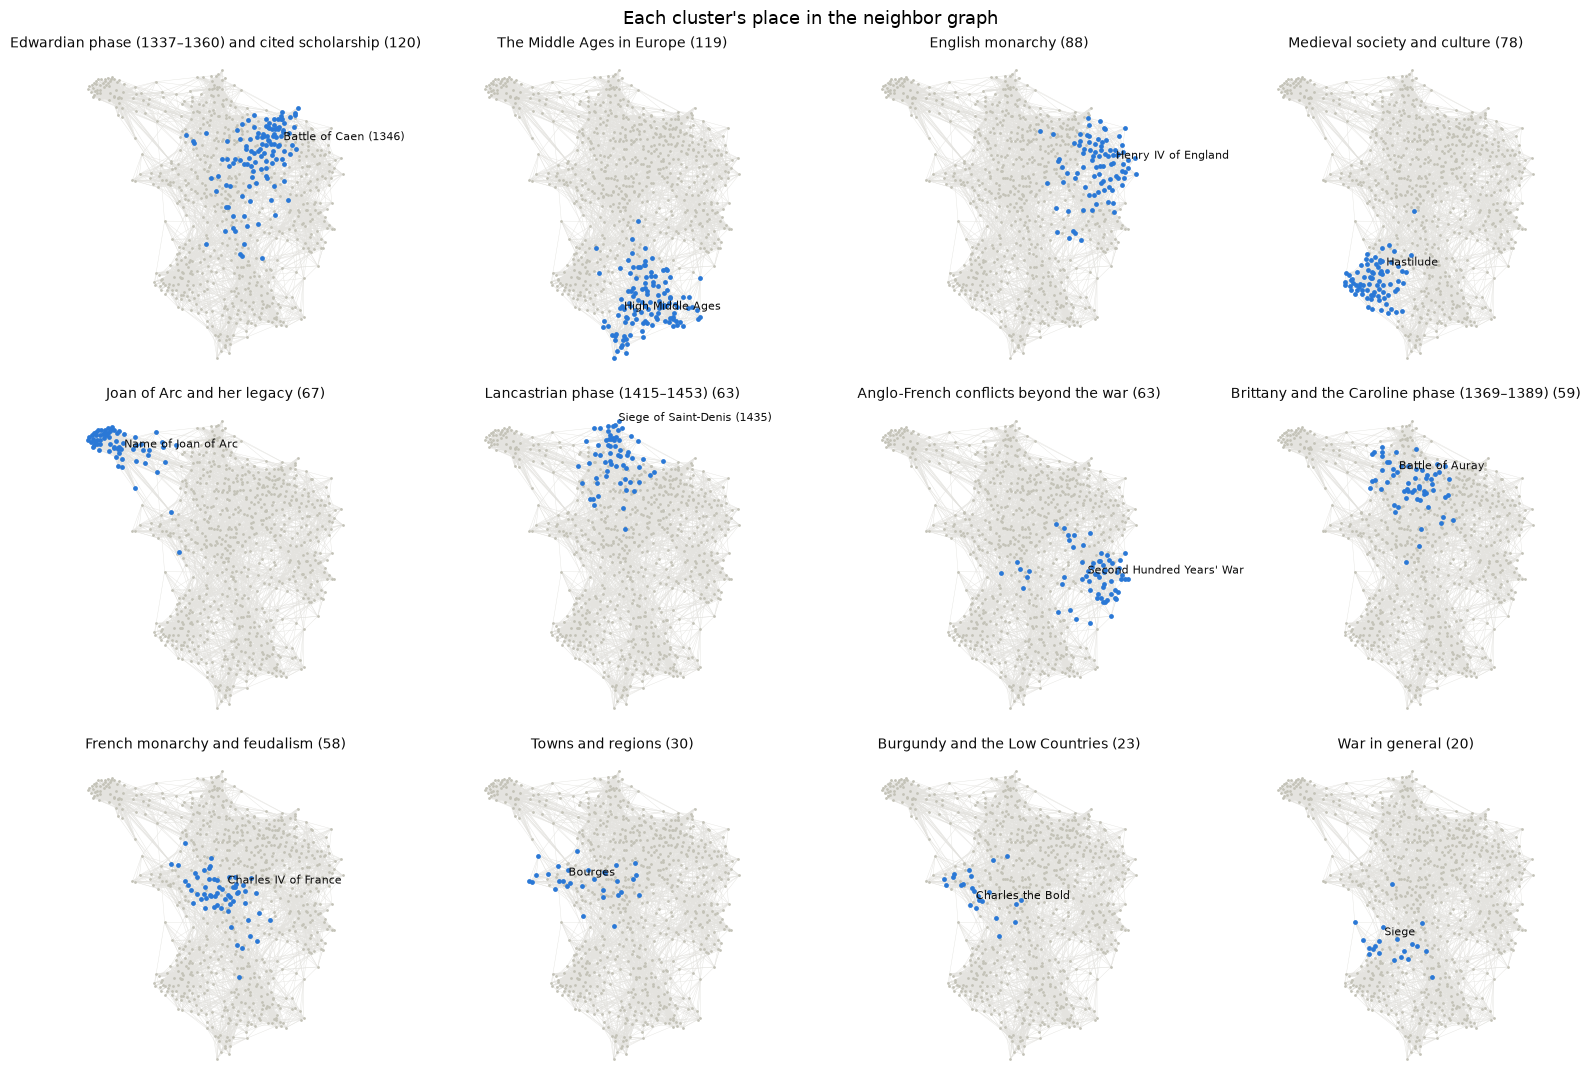

In [12]:
pos = nx.spring_layout(graph, weight="weight", seed=0)
xy = np.array([pos[t] for t in labels.index])
edges = np.array([(pos[u], pos[v]) for u, v in graph.edges()])

order = names.value_counts().index
fig, axes = plt.subplots(3, 4, figsize=(15, 11))
for ax, name in zip(axes.flat, order):
    inside = (names == name).to_numpy()
    ax.add_collection(plt.matplotlib.collections.LineCollection(edges, colors="#e4e3df", linewidths=0.3, zorder=0))
    ax.scatter(*xy[~inside].T, s=4, color="#c3c2b7", linewidths=0, zorder=1)
    ax.scatter(*xy[inside].T, s=12, color="#2a78d6", linewidths=0, zorder=2)
    hub = centrality[names == name].idxmax()
    ax.annotate(hub, pos[hub], xytext=(4, 4), textcoords="offset points", fontsize=8, color="#0b0b0b", zorder=3)
    ax.set_title(f"{name} ({inside.sum()})", fontsize=10, color="#0b0b0b")
    ax.set_axis_off()
fig.suptitle("Each cluster's place in the neighbor graph", fontsize=13)
plt.tight_layout()

### Bridge articles
Some articles get pulled between themes. An article's outside share is the fraction of its 10 most similar articles that are in other clusters. Most articles have none (median 0), and the ones with the highest share are bridges between themes.

In [13]:
outside = clustering.outside_share(mw, labels, K)
neighbor_names = names[mw.index].to_numpy()[clustering.neighbors(mw, K)]

def main_outside_cluster(title):
    row = neighbor_names[mw.index.get_loc(title)]
    others = pd.Series(row[row != names[title]])
    return others.mode().iloc[0] if len(others) else ""

bridges = outside.sort_values(ascending=False).head(10).index
pd.DataFrame({
    "outside share": outside[bridges],
    "cluster": names[bridges],
    "most neighbors outside are in": [main_outside_cluster(t) for t in bridges],
})

,outside share,cluster,most neighbors outside are in
Feudalism,1.0,French monarchy and feudalism,The Middle Ages in Europe
Battle of Jargeau,0.9,Lancastrian phase (1415–1453),Joan of Arc and her legacy
Kingdom of France,0.9,Anglo-French conflicts beyond the war,The Middle Ages in Europe
Piracy,0.8,War in general,The Middle Ages in Europe
Military history of France,0.8,Anglo-French conflicts beyond the war,French monarchy and feudalism
Duchy of Aquitaine,0.8,Towns and regions,French monarchy and feudalism
Urban T. Holmes Jr.,0.8,Edwardian phase (1337–1360) and cited scholarship,Joan of Arc and her legacy
Harelle,0.8,English monarchy,Edwardian phase (1337–1360) and cited scholarship
Armagnac–Burgundian Civil War,0.8,Burgundy and the Low Countries,Lancastrian phase (1415–1453)
Castilian Civil War of 1351–1369,0.8,Brittany and the Caroline phase (1369–1389),Lancastrian phase (1415–1453)


## 6. Save

`clusters.parquet`: one row per article (seed excluded) with its cluster number, name, centrality and outside share.

In [14]:
clusters = pd.DataFrame({
    "cluster": labels, "cluster_name": names, "centrality": centrality, "outside_share": outside,
}).loc[labels.index].rename_axis("title").reset_index()

assert len(clusters) == 788 and clusters["title"].is_unique, "one row per article"
assert SEED not in set(clusters["title"]), "seed excluded"
assert clusters["cluster_name"].notna().all(), "every article named"
assert clusters.set_index("title")["cluster"].equals(clustering.louvain(graph).rename_axis("title")), "reproducible"

clusters.to_parquet(data / "clusters.parquet", index=False)
clusters.to_csv(data / "clusters.csv", index=False, encoding="utf-8-sig")
print(f"saved clusters ({len(clusters)} rows, {clusters['cluster'].nunique()} clusters)")

saved clusters (788 rows, 12 clusters)


## Findings

- 12 themes: the war's three phases (Edwardian, 1337–1360, together with the scholarship its articles cite; Brittany and the Caroline phase, 1369–1389; Lancastrian, 1415–1453), Joan of Arc and her legacy, the English and French monarchies, Burgundy and the Low Countries, Anglo-French conflicts beyond the war, the Middle Ages in Europe, medieval society and culture, towns and regions, and war in general.
- Naming took more than the core of each cluster. The Edwardian cluster's 10 most central articles are all battles and campaigns, but 56 of its 120 articles are scholarship and media sitting at its edge. Three clusters mostly rebuild a navbox: Medieval society and culture (75 of 78 in the *Middle Ages* navbox), The Middle Ages in Europe (93 of 119 in *History of Europe*) and Joan of Arc and her legacy (63 of 67 in *Joan of Arc*).
- The clusters are stable: ARI 0.89 across random seeds (11 to 13 clusters), 0.79 on random 80% subsets and 0.77 with K = 15. With K = 5 they split into 16 smaller clusters (ARI 0.65).
- Silhouette alone is misleading. Average-linkage hierarchical clustering scores higher (0.28 vs 0.21 for Louvain) while putting 765 of the 788 articles in one cluster.
- Theme and closeness are different things. The Lancastrian phase, Joan of Arc and medieval society are closest to the seed (median rank around 230 to 260), while the Edwardian phase, towns and regions, and war in general are farthest (570 to 690). The Edwardian cluster is far partly because of its many short articles (median about 860 words), half of which don't link back to the war, and partly because of the scholarship at its edge.
- Medieval society is 94% template-linked from the seed but still ranks second closest, which is the navbox effect from notebook 02. The two monarchies and the towns are only 0–22% template-linked, so most of the structure isn't navboxes.
- Bridges: *Battle of Jargeau* sits in the Lancastrian phase, but 9 of its 10 nearest articles are in other clusters, mostly Joan of Arc. *Feudalism* and *Kingdom of France* sit between their cluster and the Middle Ages.